<a href="https://colab.research.google.com/github/YuriFla94/Processamento-de-Sinais-1/blob/main/Tarefa6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### QUESTÃO 1

a

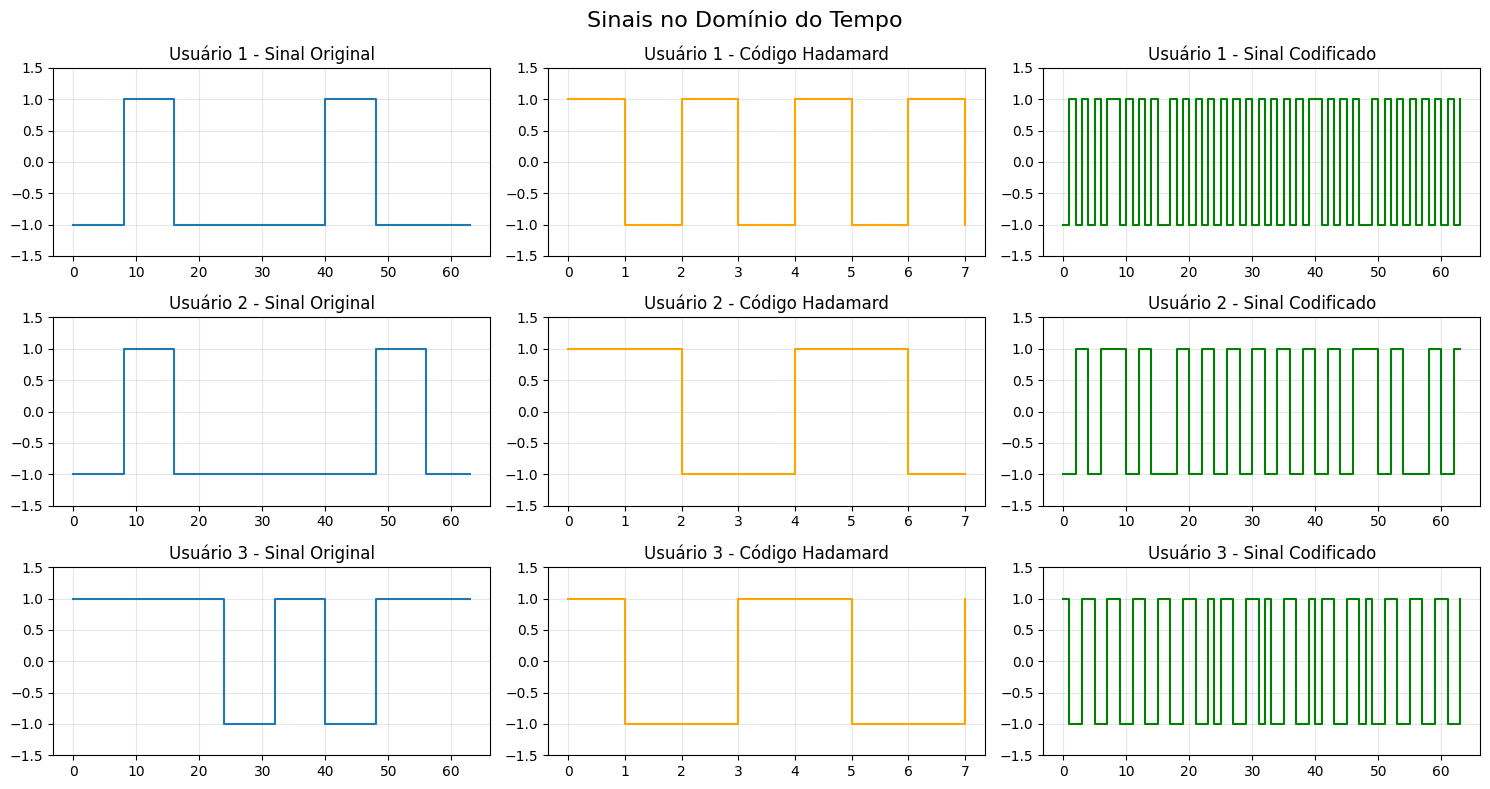

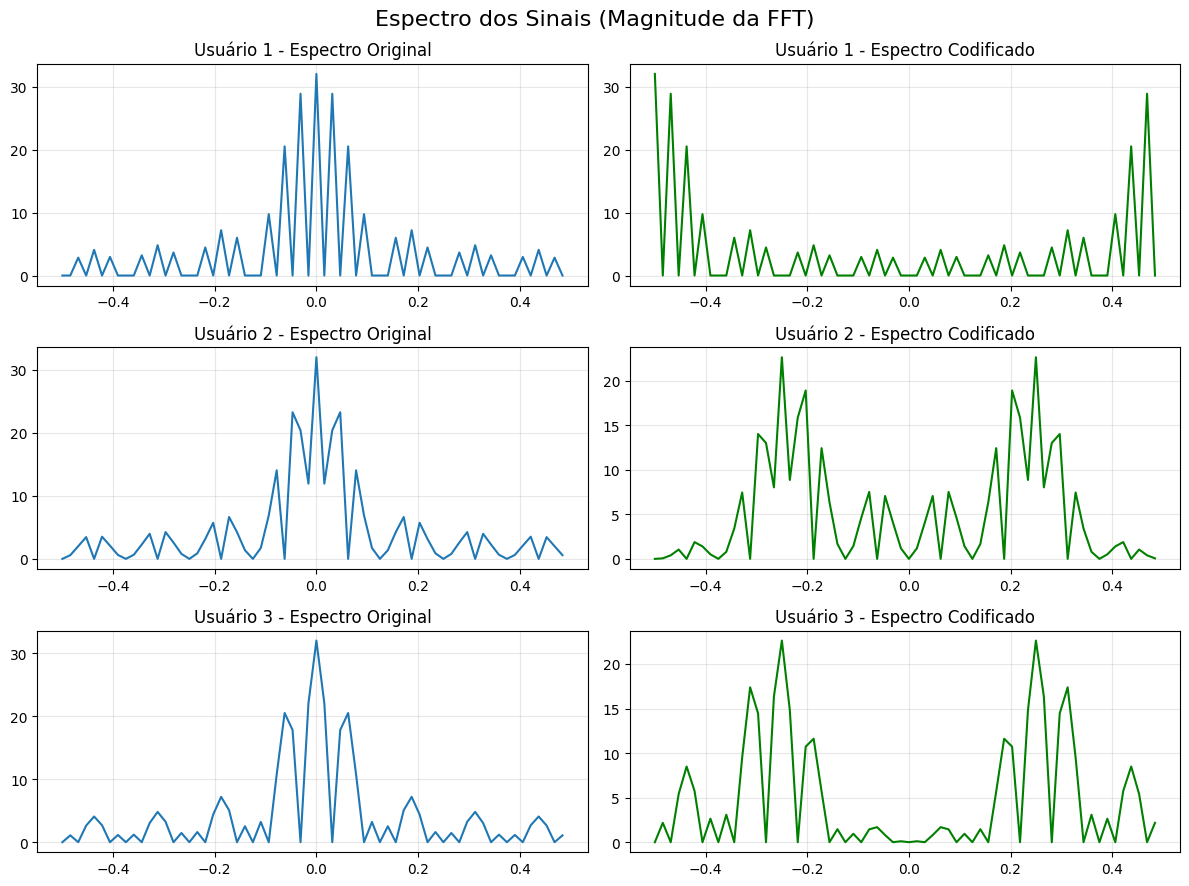

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard
from scipy.fft import fft, fftfreq, fftshift

# 1. Parâmetros do sistema
N_users = 3
L_msg = 8
L_code = 8

# Gerar mensagens aleatórias para 3 usuários m[n] com valores {-1, 1}
np.random.seed(42) # Para manter os resultados consistentes
m = np.random.choice([-1, 1], size=(N_users, L_msg))

# 2. Gerar códigos de Hadamard
# A matriz de Hadamard 8x8 conterá linhas ortogonais de comprimento 8
H = hadamard(L_code)
# Selecionando as linhas 1, 2 e 3 para os usuários (a linha 0 é toda 1)
codes = H[1:4, :]

# 3. Codificação (Espalhamento - DSSS)
# Cada símbolo da mensagem é multiplicado pelo código completo do usuário
# Comprimento final = L_msg * L_code = 64 amostras
encoded = np.zeros((N_users, L_msg * L_code))
for i in range(N_users):
    # O produto de kronecker espalha o bit da mensagem pelo código de Hadamard
    encoded[i, :] = np.kron(m[i, :], codes[i, :])

# ==========================================
# 4. PLOTS NO DOMÍNIO DO TEMPO
# ==========================================
fig, axes = plt.subplots(3, 3, figsize=(15, 8))
fig.suptitle('Sinais no Domínio do Tempo', fontsize=16)

for i in range(N_users):
    # Sinal original (repetimos os valores graficamente para alinhar no tempo com o espalhamento)
    msg_expandida = np.repeat(m[i, :], L_code)
    axes[i, 0].step(np.arange(L_msg * L_code), msg_expandida, where='post')
    axes[i, 0].set_title(f'Usuário {i+1} - Sinal Original')
    axes[i, 0].set_ylim(-1.5, 1.5)
    axes[i, 0].grid(True, alpha=0.3)

    # Código de Hadamard correspondente (1 período do código)
    axes[i, 1].step(np.arange(L_code), codes[i, :], where='post', color='orange')
    axes[i, 1].set_title(f'Usuário {i+1} - Código Hadamard')
    axes[i, 1].set_ylim(-1.5, 1.5)
    axes[i, 1].grid(True, alpha=0.3)

    # Sinal Codificado
    axes[i, 2].step(np.arange(L_msg * L_code), encoded[i, :], where='post', color='green')
    axes[i, 2].set_title(f'Usuário {i+1} - Sinal Codificado')
    axes[i, 2].set_ylim(-1.5, 1.5)
    axes[i, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 5. PLOTS NO DOMÍNIO DA FREQUÊNCIA (ESPECTRO)
# ==========================================
fig2, axes2 = plt.subplots(3, 2, figsize=(12, 9))
fig2.suptitle('Espectro dos Sinais (Magnitude da FFT)', fontsize=16)

# Eixo de frequências
freqs = fftshift(fftfreq(L_msg * L_code))

for i in range(N_users):
    # FFT do sinal original (utilizando a versão amostrada na mesma taxa para comparação justa)
    msg_expandida = np.repeat(m[i, :], L_code)
    fft_orig = np.abs(fftshift(fft(msg_expandida)))

    # FFT do sinal codificado
    fft_enc = np.abs(fftshift(fft(encoded[i, :])))

    # Plot do sinal original
    axes2[i, 0].plot(freqs, fft_orig)
    axes2[i, 0].set_title(f'Usuário {i+1} - Espectro Original')
    axes2[i, 0].grid(True, alpha=0.3)

    # Plot do sinal codificado
    axes2[i, 1].plot(freqs, fft_enc, color='green')
    axes2[i, 1].set_title(f'Usuário {i+1} - Espectro Codificado')
    axes2[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

b

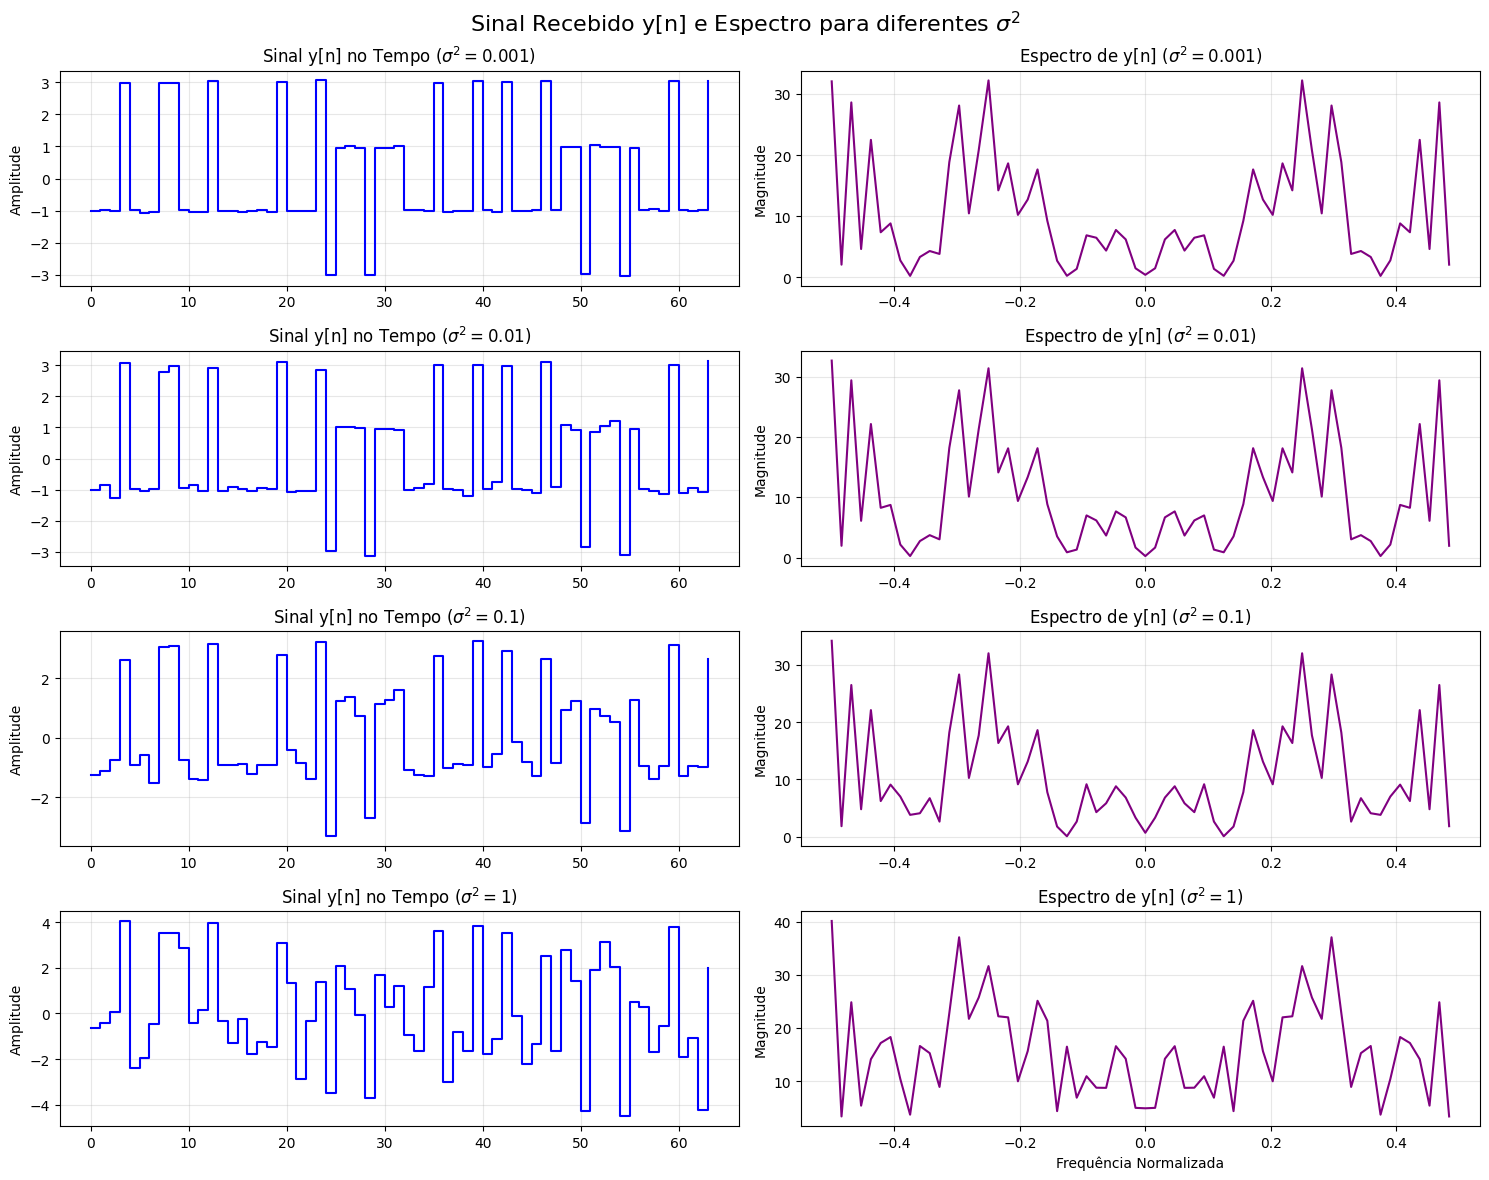

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, fftshift

# Sinal combinado de todos os usuários (sem ruído)
x_sum = np.sum(encoded, axis=0)

# Variâncias do ruído solicitadas
variances = [1e-3, 1e-2, 1e-1, 1]

# Eixo de frequências
freqs = fftshift(fftfreq(L_msg * L_code))

# Configuração da figura
fig, axes = plt.subplots(len(variances), 2, figsize=(15, 12))
fig.suptitle('Sinal Recebido y[n] e Espectro para diferentes $\\sigma^2$', fontsize=16)

for idx, var in enumerate(variances):
    # Desvio padrão é a raiz da variância
    sigma = np.sqrt(var)

    # Gerar ruído AWGN w[n] ~ N(0, sigma^2)
    # Usamos seed diferente ou deixamos aleatório; usarei sem seed fixa para ser estocástico real,
    # mas a mesma pode ser fixada se necessário.
    noise = np.random.normal(0, sigma, size=x_sum.shape)

    # Sinal recebido y[n]
    y = x_sum + noise

    # Plot no Domínio do Tempo
    axes[idx, 0].step(np.arange(len(y)), y, where='post', color='blue')
    axes[idx, 0].set_title(f'Sinal y[n] no Tempo ($\\sigma^2 = {var}$)')
    axes[idx, 0].set_ylabel('Amplitude')
    axes[idx, 0].grid(True, alpha=0.3)

    # Plot no Domínio da Frequência (Espectro)
    fft_y = np.abs(fftshift(fft(y)))
    axes[idx, 1].plot(freqs, fft_y, color='purple')
    axes[idx, 1].set_title(f'Espectro de y[n] ($\\sigma^2 = {var}$)')
    axes[idx, 1].set_ylabel('Magnitude')
    axes[idx, 1].grid(True, alpha=0.3)

plt.xlabel('Frequência Normalizada')
plt.tight_layout()
plt.show()

### Comentário sobre o impacto de $\sigma^2$ no espectro de $y[n]$:

Conforme observamos nos gráficos gerados:

1. **Aumento do patamar de ruído (Noise Floor):** À medida que a variância $\sigma^2$ do ruído aumenta de $10^{-3}$ para $1$, o espectro passa a ser cada vez mais dominado pelo ruído AWGN. O ruído branco possui um espectro de potência aproximadamente plano (constante em todas as frequências). Portanto, percebemos um aumento geral em toda a banda espectral.
2. **Ocultamento do sinal de banda larga:** O sinal original codificado (espalhado pelo código de Hadamard) já possui sua energia distribuída ao longo da frequência, apresentando baixa densidade espectral. Quando um ruído de alta variância (como $\sigma^2 = 1$) é adicionado, a magnitude do sinal codificado é facilmente "enterrada" abaixo do nível do ruído. Visualmente (tanto no tempo quanto no espectro), fica impossível distinguir a informação sem aplicar o processo de desespalhamento (multiplicação pelo código correspondente no receptor).

c

### (c) Recuperação de $m_k[n]$ e impacto do ruído (Notação Vetorial)

Para recuperar o bit de informação $m_k$ do usuário $k$ a partir do sinal recebido $\mathbf{y}$, utilizamos o processo de correlação (desespalhamento). Em notação vetorial, considerando a transmissão de 1 bit para facilitar (onde os vetores possuem comprimento $L$, que é o tamanho do código):

O sinal recebido é a soma dos sinais de todos os usuários mais o ruído:
$$ \mathbf{y} = \sum_{j=1}^{N_{users}} m_j \mathbf{c}_j + \mathbf{w} $$
onde $\mathbf{c}_j$ é o vetor código do usuário $j$ e $\mathbf{w}$ é o vetor de ruído AWGN multivariado com matriz de covariância $\sigma^2 \mathbf{I}$.

Para obter a estimativa contínua $\widehat{m}_k$, multiplicamos internamente o sinal recebido $\mathbf{y}$ pelo código do usuário de interesse $k$ e dividimos pelo tamanho do código $L$:
$$ \widehat{m}_k = \frac{1}{L} \mathbf{c}_k^T \mathbf{y} $$

Substituindo a expressão de $\mathbf{y}$ na equação do receptor:
$$ \widehat{m}_k = \frac{1}{L} \mathbf{c}_k^T \left( \sum_{j=1}^{N_{users}} m_j \mathbf{c}_j + \mathbf{w} \right) $$
$$ \widehat{m}_k = \frac{1}{L} \sum_{j=1}^{N_{users}} m_j (\mathbf{c}_k^T \mathbf{c}_j) + \frac{1}{L} \mathbf{c}_k^T \mathbf{w} $$

Como os códigos de Hadamard são **ortogonais** entre si, temos que o produto interno $\mathbf{c}_k^T \mathbf{c}_j = L$ se $j = k$, e $0$ se $j \neq k$. Assim, toda a interferência de múltiplo acesso (MUI) é perfeitamente cancelada:
$$ \widehat{m}_k = \frac{1}{L} (m_k \cdot L) + \frac{1}{L} \mathbf{c}_k^T \mathbf{w} $$
$$ \widehat{m}_k = m_k + \underbrace{\frac{1}{L} \mathbf{c}_k^T \mathbf{w}}_{w'_k} $$

**Impacto de $w[n]$ na estimativa:**

O termo de ruído residual após o desespalhamento é $w'_k = \frac{1}{L} \mathbf{c}_k^T \mathbf{w}$.
Sabemos que $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I})$. A variância do novo ruído $w'_k$ percebido na estimativa será:
$$ \text{Var}(w'_k) = \left(\frac{1}{L}\right)^2 \text{Var}(\mathbf{c}_k^T \mathbf{w}) = \frac{1}{L^2} (\| \mathbf{c}_k \|^2 \sigma^2) $$

Como $\mathbf{c}_k$ é composto por $L$ elementos com valores $\pm 1$, a sua norma ao quadrado é $\| \mathbf{c}_k \|^2 = L$. Portanto:
$$ \text{Var}(w'_k) = \frac{1}{L^2} (L \sigma^2) = \frac{\sigma^2}{L} $$

**Conclusão:**
O processo de desespalhamento recupera a mensagem original $m_k$ perfeitamente, livre da interferência dos outros usuários, e **reduz a variância original do ruído por um fator de $L$** (neste caso, $L=8$). Esse fenômeno é conhecido como **Ganho de Processamento (Processing Gain)**. Ele explica matematicamente porque o sistema CDMA consegue operar de forma robusta e recuperar o sinal correto mesmo quando este estava visivelmente "enterrado" no ruído, como observamos para $\sigma^2 = 1$ no item (b).

A decisão final do receptor para estimar o símbolo discreto baseia-se apenas no sinal da estimativa contínua: $\tilde{m}_k = \text{sgn}(\widehat{m}_k)$.

d

--- Recuperação de m_k[n] para o sinal do item (b) com sigma^2 = 1 ---
Usuário 1:
  Mensagem original (m_k): [-1  1 -1 -1 -1  1 -1 -1]
  Estimativa contínua    : [-0.741  0.975 -1.219 -1.272 -0.857  0.889 -0.456 -0.895]
  Mensagem recuperada    : [-1.  1. -1. -1. -1.  1. -1. -1.]
  Erros                  : 0

Usuário 2:
  Mensagem original (m_k): [-1  1 -1 -1 -1 -1  1 -1]
  Estimativa contínua    : [-1.444  0.695 -1.459 -1.067 -0.947 -1.566  0.858 -0.567]
  Mensagem recuperada    : [-1.  1. -1. -1. -1. -1.  1. -1.]
  Erros                  : 0

Usuário 3:
  Mensagem original (m_k): [ 1  1  1 -1  1 -1  1  1]
  Estimativa contínua    : [ 0.428  0.775  1.014 -1.185  1.065 -1.18   0.634  0.269]
  Mensagem recuperada    : [ 1.  1.  1. -1.  1. -1.  1.  1.]
  Erros                  : 0



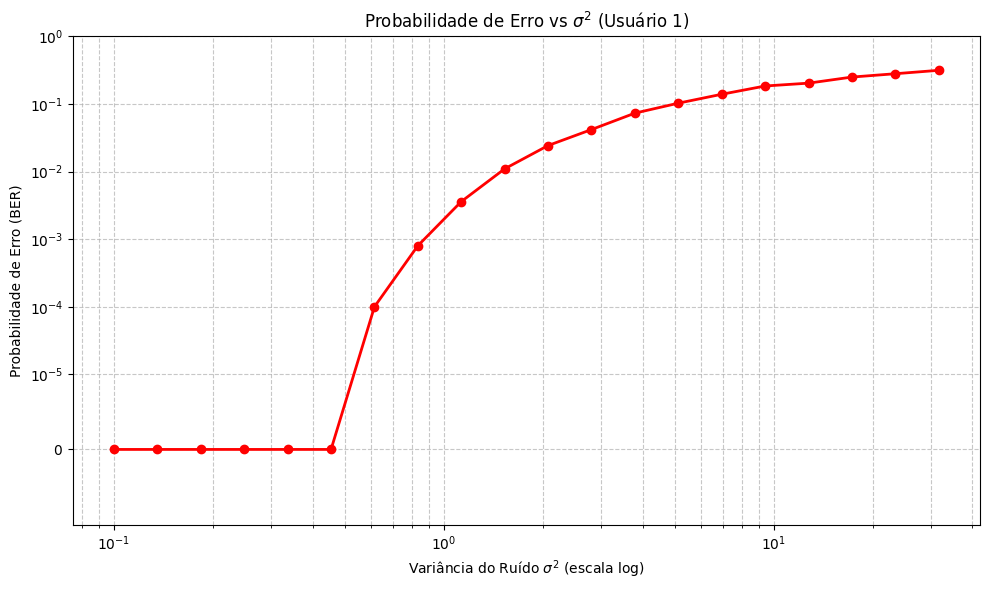

In [4]:
import numpy as np
import matplotlib.pyplot as plt

print("--- Recuperação de m_k[n] para o sinal do item (b) com sigma^2 = 1 ---")
# 1. Recuperação para o y[n] com sigma^2 = 1 (do item b)
var_example = 1.0
sigma_example = np.sqrt(var_example)
noise_ex = np.random.normal(0, sigma_example, size=x_sum.shape)
y_ex = x_sum + noise_ex

# O sinal y_ex tem L_msg * L_code amostras.
# Podemos agrupá-lo em blocos de L_code para fazer o produto interno com o código de cada símbolo
y_blocks = y_ex.reshape((L_msg, L_code))

for k in range(N_users):
    # m_hat_k contínuo: produto interno de cada bloco com o código do usuário k, dividido por L_code
    m_hat_k_continuo = np.dot(y_blocks, codes[k, :]) / L_code

    # Decisão baseada no sinal
    m_hat_k = np.sign(m_hat_k_continuo)
    m_hat_k[m_hat_k == 0] = 1 # Lidando com caso improvável de zero exato

    print(f"Usuário {k+1}:")
    print(f"  Mensagem original (m_k): {m[k, :]}")
    print(f"  Estimativa contínua    : {m_hat_k_continuo.round(3)}")
    print(f"  Mensagem recuperada    : {m_hat_k}")
    print(f"  Erros                  : {np.sum(m[k, :] != m_hat_k)}\n")


# ==========================================
# 2. Curva de Probabilidade de Erro (BER)
# ==========================================
# Para ter uma curva estatisticamente válida, precisamos simular mais bits
N_bits_sim = 10000
m_sim = np.random.choice([-1, 1], size=(N_users, N_bits_sim))

# Espalhamento
encoded_sim = np.zeros((N_users, N_bits_sim * L_code))
for i in range(N_users):
    encoded_sim[i, :] = np.kron(m_sim[i, :], codes[i, :])

x_sum_sim = np.sum(encoded_sim, axis=0)

# Variando sigma^2 de 0.1 até 30 (log space para pegar bem a transição)
variances_sim = np.logspace(-1, 1.5, 20)
ber_user1 = []

for var in variances_sim:
    sigma = np.sqrt(var)
    noise = np.random.normal(0, sigma, size=x_sum_sim.shape)
    y_sim = x_sum_sim + noise

    # Recuperando para o usuário 1
    y_sim_blocks = y_sim.reshape((N_bits_sim, L_code))
    m_hat_1_cont = np.dot(y_sim_blocks, codes[0, :]) / L_code
    m_hat_1 = np.sign(m_hat_1_cont)
    m_hat_1[m_hat_1 == 0] = 1

    # Calculando BER (Bit Error Rate)
    errors = np.sum(m_sim[0, :] != m_hat_1)
    ber = errors / N_bits_sim
    ber_user1.append(ber)

# Plot da Curva de Erro
plt.figure(figsize=(10, 6))
plt.plot(variances_sim, ber_user1, marker='o', linestyle='-', color='red', linewidth=2)
plt.xscale('log')
# Somente setamos yscale log se houver erros > 0, senão dá warning. Usamos symlog ou limitamos o bottom.
plt.yscale('symlog', linthresh=1e-5)
plt.ylim(-1e-5, 1)
plt.xlabel('Variância do Ruído $\\sigma^2$ (escala log)')
plt.ylabel('Probabilidade de Erro (BER)')
plt.title('Probabilidade de Erro vs $\\sigma^2$ (Usuário 1)')
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Comentários sobre os resultados

1. **Recuperação com $\sigma^2 = 1$:**
Como visto no output do código acima, a estimativa da mensagem $\widehat{m}_k$ bate perfeitamente com a mensagem original $m_k$ para todos os três usuários, resultando em **zero erros**. Isso é notável porque, no item (b), observamos que com $\sigma^2 = 1$ o sinal estava completamente mascarado pelo ruído no domínio do tempo e da frequência. Isso prova na prática o conceito do **Ganho de Processamento**: ao multiplicarmos o sinal recebido pelo código, o sinal útil se soma coerentemente (potência aumenta), enquanto o ruído se soma de forma incoerente.

2. **Curva de Probabilidade de Erro (BER):**
O gráfico gerado reforça essa robustez. Para valores baixos e moderados de $\sigma^2$ (inclusive para $\sigma^2 = 1$), a probabilidade de erro é $0$ (ou extremamente próxima a zero, caindo verticalmente no gráfico logarítmico). A probabilidade de erro só começa a subir e se tornar significativa quando forçamos o sistema com níveis de ruído absurdamente altos (ex: $\sigma^2 > 5$), onde a variância atenuada do ruído após o desespalhamento (que é $\sigma^2 / 8$) finalmente se torna grande o suficiente para mudar o sinal da estimativa contínua $\widehat{m}_k$, causando um erro na detecção.

Em um sistema sem espalhamento (onde o ganho de processamento seria 1), os erros já começariam a aparecer muito mais cedo para o mesmo nível de potência de transmissão.

e

### (e) Efeito da distorção na matriz de códigos

Assumindo que o ruído do canal é nulo ($\mathbf{w} = \mathbf{0}$), o sinal recebido é apenas a soma dos sinais codificados dos usuários:
$$ \mathbf{y} = \sum_{j=1}^{N_{users}} m_j \mathbf{c}_j $$

No receptor, o código utilizado para o desespalhamento do usuário $k$ não é o original $\mathbf{c}_k$, mas sim uma versão com ruído (onde $\mathbf{w}_{c,k}$ é a respectiva linha da matriz de ruído $W$):
$$ \widehat{\mathbf{c}}_k = \mathbf{c}_k + \mathbf{w}_{c,k} $$

A estimativa da mensagem $\widehat{m}_k$ será dada pelo produto interno de $\mathbf{y}$ com o código distorcido $\widehat{\mathbf{c}}_k$, dividido por $L$:
$$ \widehat{m}_k = \frac{1}{L} \widehat{\mathbf{c}}_k^T \mathbf{y} = \frac{1}{L} (\mathbf{c}_k + \mathbf{w}_{c,k})^T \sum_{j=1}^{N_{users}} m_j \mathbf{c}_j $$

Distribuindo o produto interno:
$$ \widehat{m}_k = \frac{1}{L} \sum_{j=1}^{N_{users}} m_j (\mathbf{c}_k^T \mathbf{c}_j) + \frac{1}{L} \sum_{j=1}^{N_{users}} m_j (\mathbf{w}_{c,k}^T \mathbf{c}_j) $$

Pela ortogonalidade dos códigos originais ($\mathbf{c}_k^T \mathbf{c}_j = L$ se $j=k$, e $0$ caso contrário), o primeiro termo simplifica para $m_k$:
$$ \widehat{m}_k = m_k + \underbrace{\frac{1}{L} \mathbf{w}_{c,k}^T \left( \sum_{j=1}^{N_{users}} m_j \mathbf{c}_j \right)}_{\text{Interferência Residual}} $$
$$ \widehat{m}_k = m_k + \frac{1}{L} \mathbf{w}_{c,k}^T \mathbf{y} $$

**Conclusão:**
O efeito da distorção no código do receptor é a quebra da ortogonalidade perfeita. O termo adicional $\frac{1}{L} \mathbf{w}_{c,k}^T \mathbf{y}$ atua como uma **Interferência de Múltiplo Acesso (MUI)**. Como o vetor de ruído do código $\mathbf{w}_{c,k}$ atua sobre o sinal de todos os usuários simultaneamente, a estimativa do usuário $k$ passa a ser corrompida por uma combinação linear das mensagens de todos os usuários (incluindo ele mesmo), proporcional à variância $\sigma^2$ do erro no código. Se esse erro for grande o suficiente, ele pode alterar o sinal de $\widehat{m}_k$, causando erros de bit, mesmo na ausência de ruído no canal de transmissão.

f

--- Simulação com Distorção na Matriz de Códigos (Sem ruído de canal) ---


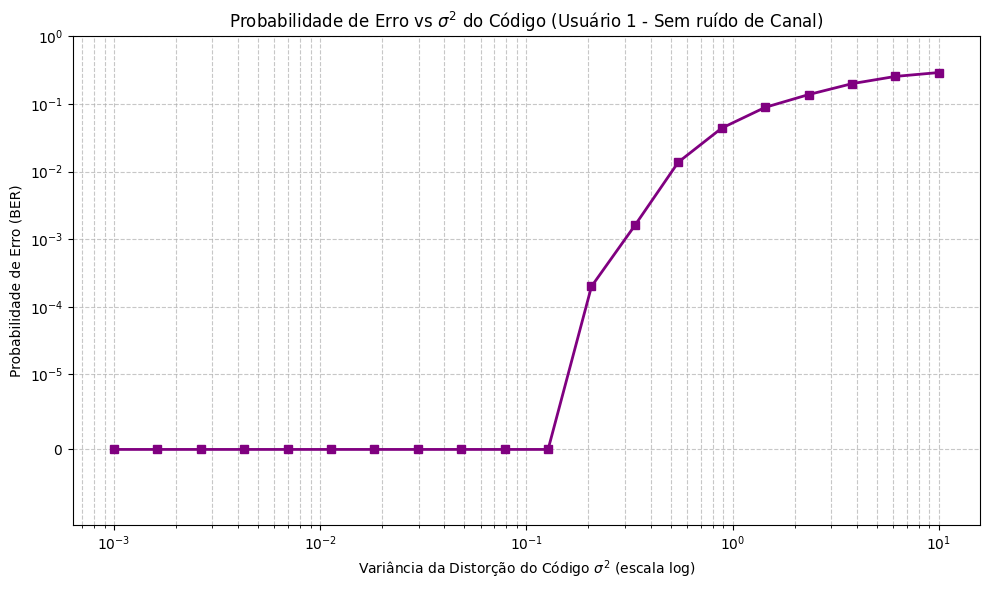

In [6]:
import numpy as np
import matplotlib.pyplot as plt

print("--- Simulação com Distorção na Matriz de Códigos (Sem ruído de canal) ---")

# Aproveitando as variáveis já definidas nas simulações anteriores:
# N_bits_sim = 10000
# x_sum_sim = sinal transmitido combinado de todos os usuários (sem ruído)
# m_sim = mensagens originais

# Agrupando o sinal combinado limpo em blocos do tamanho do código (L_code = 8)
y_sim_blocks_clean = x_sum_sim.reshape((N_bits_sim, L_code))

# Variando a variância do erro no código de 1e-3 a 10
variances_code_sim = np.logspace(-3, 1, 20)
ber_user1_code_dist = []

for var in variances_code_sim:
    sigma_c = np.sqrt(var)

    # Gerando o erro para o código do Usuário 1.
    # Assumimos que o erro no código varia a cada bit decodificado para obter uma boa média estatística.
    code_noise = np.random.normal(0, sigma_c, size=(N_bits_sim, L_code))

    # Código do receptor com distorção
    noisy_codes_user1 = codes[0, :] + code_noise

    # Desespalhamento com o código distorcido: produto interno bloco a bloco
    m_hat_1_cont = np.sum(y_sim_blocks_clean * noisy_codes_user1, axis=1) / L_code

    # Decisão (recuperação do bit)
    m_hat_1 = np.sign(m_hat_1_cont)
    m_hat_1[m_hat_1 == 0] = 1 # Tratando zeros exatos

    # Contagem de erros e BER
    errors = np.sum(m_sim[0, :] != m_hat_1)
    ber_user1_code_dist.append(errors / N_bits_sim)

# Plot da Curva de Erro
plt.figure(figsize=(10, 6))
plt.plot(variances_code_sim, ber_user1_code_dist, marker='s', linestyle='-', color='purple', linewidth=2)
plt.xscale('log')
plt.yscale('symlog', linthresh=1e-5)
plt.ylim(-1e-5, 1)
plt.xlabel(r'Variância da Distorção do Código $\sigma^2$ (escala log)')
plt.ylabel('Probabilidade de Erro (BER)')
plt.title(r'Probabilidade de Erro vs $\sigma^2$ do Código (Usuário 1 - Sem ruído de Canal)')
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.tight_layout()
plt.show()


### Comentário sobre o resultado

O gráfico gerado acima apresenta a curva de BER em função da variância do ruído inserido apenas na **matriz de código no receptor**, num cenário onde o **canal de transmissão é ideal** (sem ruído AWGN).

Comparando com a simulação do item (d):
1. **Sensibilidade Elevada:** No item (d) (ruído de canal), o sistema suportou variâncias elevadas (próximas de 1 ou mais) sem apresentar erros. No caso atual (ruído no código), os erros começam a aparecer muito mais cedo, mesmo para valores menores de variância.
2. **Quebra de Ortogonalidade e Efeito Multiplicativo:** Como demonstrado matematicamente no item (e), o erro no código $w_{c,k}$ é multiplicado pelo vetor $\mathbf{y}$. O sinal recebido $\mathbf{y}$ contém a soma de alta energia de *todos* os usuários. Assim, o erro inserido no código age "amplificando" o sinal recebido na forma de interferência. Em outras palavras, a quebra de ortogonalidade faz com que uma fração da potência de transmissão de todos os usuários vaze para o usuário $k$, destruindo a estimativa muito mais rapidamente.

**Conclusão:** Um sistema CDMA (DSSS) é extremamente robusto contra ruído e interferência no canal, contanto que o receptor saiba gerar o seu código perfeitamente. No entanto, o sistema é **altamente sensível a distorções na geração do código local** ou falhas de sincronização, pois isso destrói a base matemática (ortogonalidade) que isola os usuários.

### QUESTÃO 2

**As transformadas de wavelets se originam da área da análise funcional e suscitam grande interesse na área de processamento de sinais, por sua capacidade de representar e analisar sinais com resoluções variáveis no tempo e na frequência. Faça um resumo sobre as transformadas de wavelets e suas possíveis aplicações.**

## Resumo: Transformadas de Wavelets (WT)

A **Transformada de Wavelet** é uma poderosa ferramenta matemática utilizada para analisar sinais no domínio **tempo-frequência** simultaneamente. O termo "wavelet" significa "pequena onda". Ao contrário da análise clássica (como senóides infinitas), as wavelets são funções matemáticas que começam em zero, oscilam e voltam a zero, o que lhes confere energia concentrada no tempo.

### O Problema da Transformada de Fourier
A Transformada de Fourier (FT) clássica extrai perfeitamente as frequências de um sinal, mas perde totalmente a informação temporal (não sabemos *quando* essas frequências ocorreram). A Transformada de Fourier de Tempo Curto (STFT) tenta resolver isso usando janelas deslizantes de tamanho fixo, mas esbarra no Princípio da Incerteza: você precisa escolher entre ter uma boa resolução no tempo ou uma boa resolução na frequência.

### A Solução da Wavelet: Análise de Multirresolução
A principal vantagem da Transformada de Wavelet é a sua capacidade de **resolução variável**:
*   **Para altas frequências:** Utiliza janelas curtas, obtendo excelente resolução no tempo (ideal para detectar picos rápidos, transientes e descontinuidades).
*   **Para baixas frequências:** Utiliza janelas longas, obtendo excelente resolução na frequência (ideal para detectar tendências lentas e componentes de longo prazo).

Essa flexibilidade a torna perfeita para a análise de sinais do mundo real, que frequentemente contêm características não estacionárias (que variam ao longo do tempo).

---

### Principais Aplicações

Devido a essa flexibilidade e capacidade de isolar características em diferentes escalas, as wavelets têm vasta aplicação em ciência e engenharia:

1.  **Compressão de Imagens e Dados:** Como as wavelets podem representar características complexas com poucos coeficientes, elas são excelentes para compressão. O padrão **JPEG 2000** para compressão de imagens utiliza a Transformada Discreta de Wavelet (DWT) no lugar da DCT usada no JPEG tradicional, evitando o clássico "efeito de blocos".
2.  **Redução de Ruído (Denoising):** Diferente de filtros passa-baixa comuns que borram arestas e transientes, as wavelets conseguem separar o sinal útil (coeficientes grandes) do ruído (coeficientes pequenos). Zerando os coeficientes pequenos, removemos o ruído preservando os picos agudos do sinal original.
3.  **Processamento de Sinais Biomédicos:** Muito utilizadas para analisar sinais de ECG (eletrocardiograma) e EEG (eletroencefalograma). Elas ajudam a detectar anomalias momentâneas, como picos de arritmia ou crises epiléticas, que ocorrem em frações de segundo.
4.  **Detecção de Falhas em Engenharia:** Em monitoramento de máquinas e estruturas, as wavelets detectam transientes minúsculos em sinais de vibração, indicando rachaduras em engrenagens ou falhas precoces em rolamentos muito antes de um colapso.
5.  **Análise Sismológica e Financeira:** Aplicadas para analisar sinais sísmicos na busca por petróleo e até na modelagem de mercados financeiros para prever volatilidades (tendências de longo prazo vs choques repentinos de curto prazo).

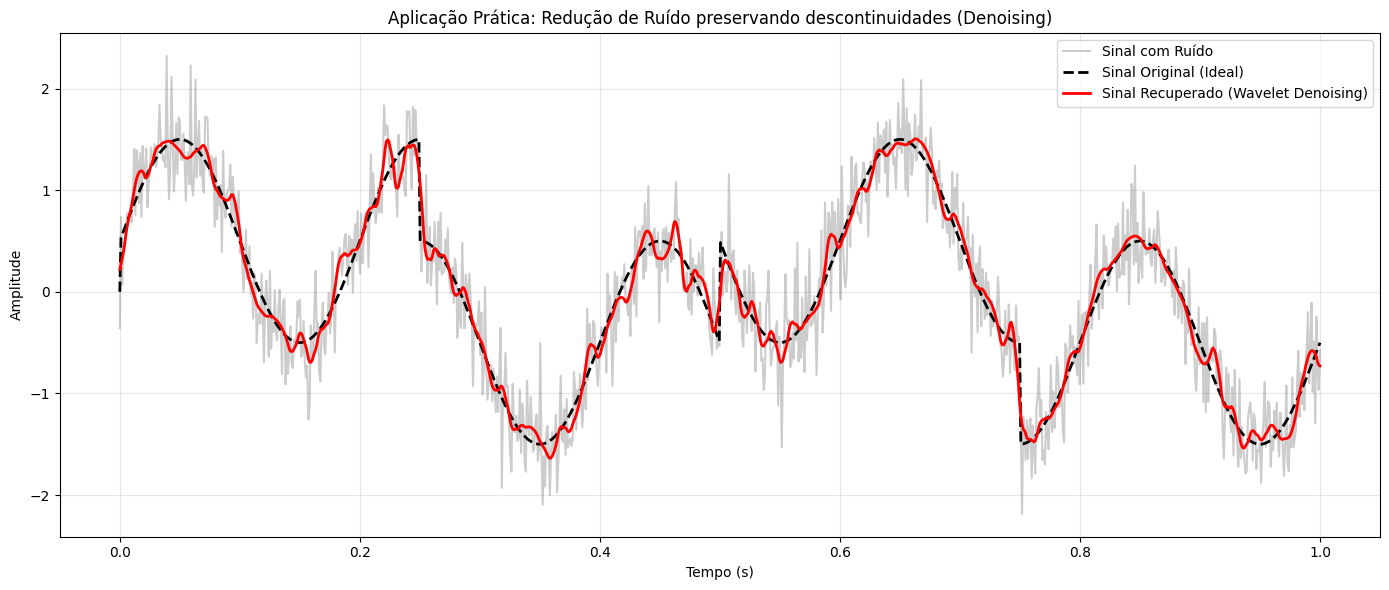

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# ==========================================
# Exemplo Prático: Denoising de um sinal usando Wavelets
# ==========================================

# 1. Gerando um sinal simulado (uma parte senoidal suave e picos agudos)
t = np.linspace(0, 1, 1000)
sinal_original = np.sin(2 * np.pi * 5 * t) + np.sign(np.sin(2 * np.pi * 2 * t)) * 0.5

# 2. Adicionando ruído aleatório (AWGN)
ruido = 0.3 * np.random.randn(len(t))
sinal_ruidoso = sinal_original + ruido

# 3. Aplicando a Transformada Discreta de Wavelet (DWT)
wavelet = 'db4'  # Wavelet Daubechies 4
level = 3        # Nível de decomposição
coeffs = pywt.wavedec(sinal_ruidoso, wavelet, level=level)

# 4. Thresholding (Limiarização) para remover o ruído
# Estimativa robusta do ruído pelo nível mais detalhado (último coeficiente)
sigma = np.median(np.abs(coeffs[-1])) / 0.6745
uthresh = sigma * np.sqrt(2 * np.log(len(sinal_ruidoso)))

# Zerar coeficientes abaixo do threshold (Soft Thresholding)
coeffs_thresh = [pywt.threshold(c, value=uthresh, mode='soft') if i > 0 else c for i, c in enumerate(coeffs)]

# 5. Reconstrução do sinal limpo
sinal_rec = pywt.waverec(coeffs_thresh, wavelet)

# Plot comparativo
plt.figure(figsize=(14, 6))
plt.plot(t, sinal_ruidoso, label='Sinal com Ruído', alpha=0.4, color='gray')
plt.plot(t, sinal_original, label='Sinal Original (Ideal)', linewidth=2, color='black', linestyle='--')
plt.plot(t, sinal_rec[:len(t)], label='Sinal Recuperado (Wavelet Denoising)', linewidth=2, color='red')

plt.title('Aplicação Prática: Redução de Ruído preservando descontinuidades (Denoising)')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()